In [230]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.metrics import precision_recall_fscore_support

import matplotlib.pyplot as plt

from imblearn.over_sampling import SMOTE

In [231]:
# VARIABLES

random_seed = 42

### Load data

In [232]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [233]:
df["Class"].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

### Feature Engineering

In [234]:
x = df.drop("Class", axis=1)
y = df["Class"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=random_seed, stratify=y)

x_train["Amount"] = np.log1p(x_train["Amount"])
x_test["Amount"] = np.log1p(x_test["Amount"])

scaler = StandardScaler()
x_train["Amount"] = scaler.fit_transform(x_train[["Amount"]])
x_test["Amount"] = scaler.transform(x_test[["Amount"]])  # Apenas transform no teste!
x_train["Time"] = scaler.fit_transform(x_train[["Time"]])
x_test["Time"] = scaler.transform(x_test[["Time"]])  # Apenas transform no teste!

### Regressão Logistica

In [288]:
model = LogisticRegression(max_iter=2000, random_state=random_seed)

model.fit(x_train, y_train)

#y_pred = model.predict(x_test)
y_prob = model.predict_proba(x_test)[:, 1]

print(f"{'Limiar':<10} | {'Precisão (Fraude)':<20} | {'Recall (Fraude)':<18} | {'F1-Score'}")
print("-" * 65)

best_f1 = 0
best_threshold = 0.5

for threshold in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    y_pred_th = (y_prob >= threshold).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred_th, average=None)
    print(f"{threshold:<10.2f} | {p[1]:<20.2%} | {r[1]:<18.2%} | {f1[1]:.4f}")

    if f1[1] > best_f1:
        best_f1 = f1[1]
        best_threshold = threshold

print("-" * 65)
print(f"Melhor Limiar: {best_threshold:.2f} com F1-Score de: {best_f1:.4f}")

# Gera a previsão final usando o melhor limiar encontrado:
y_pred = (y_prob >= best_threshold).astype(int)

Limiar     | Precisão (Fraude)    | Recall (Fraude)    | F1-Score
-----------------------------------------------------------------
0.05       | 64.75%               | 80.61%             | 0.7182
0.10       | 72.22%               | 79.59%             | 0.7573
0.20       | 73.96%               | 72.45%             | 0.7320
0.30       | 74.16%               | 67.35%             | 0.7059
0.40       | 79.27%               | 66.33%             | 0.7222
0.50       | 82.43%               | 62.24%             | 0.7093
0.60       | 83.33%               | 61.22%             | 0.7059
0.70       | 83.82%               | 58.16%             | 0.6867
0.80       | 82.81%               | 54.08%             | 0.6543
0.90       | 81.67%               | 50.00%             | 0.6203
-----------------------------------------------------------------
Melhor Limiar: 0.10 com F1-Score de: 0.7573


#### Estatisticas do Modelo

In [289]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.72      0.80      0.76        98

    accuracy                           1.00     56962
   macro avg       0.86      0.90      0.88     56962
weighted avg       1.00      1.00      1.00     56962



#### Medindo o modelo

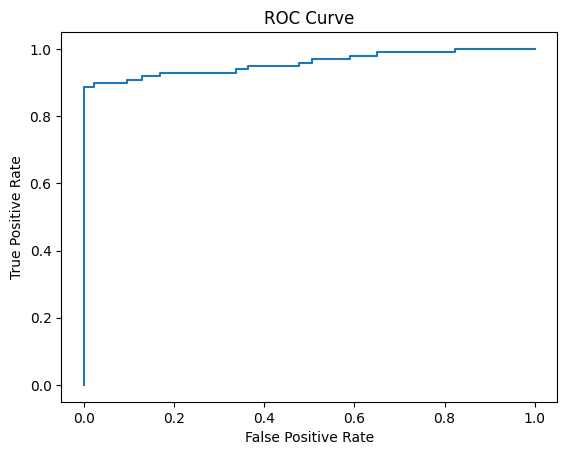

In [290]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

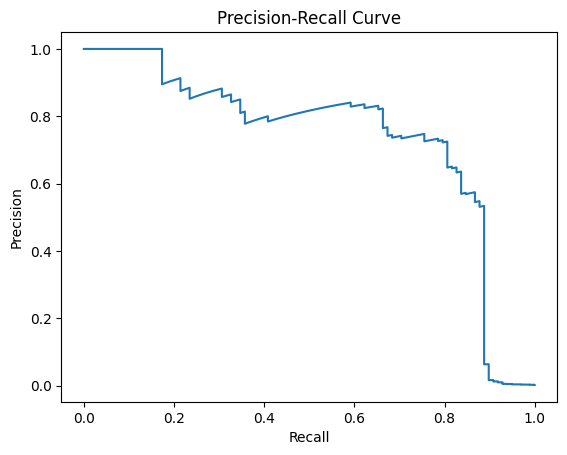

In [291]:
precision, recall, _ = precision_recall_curve(y_test, y_prob)

plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

### Data augmentation

In [292]:
# Undersampling (reduz a classe majoritaria)

#fraudes = df[df["Class"] == 1]
#normais = df[df["Class"] == 0].sample(len(fraudes), random_state=random_seed)
#df = pd.concat([fraudes, normais])

# Oversampling (aumenta a classe minoritaria)
# O oversampling aumentou a classe minoritaria porém derrubou a acuracia entao desativei
#smote = SMOTE(random_state=random_seed, sampling_strategy=0.05)
#x_train, y_train = smote.fit_resample(x_train, y_train)